In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import mannwhitneyu
from statsmodels.stats.multitest import multipletests

print("Libraries loaded successfully.")

Libraries loaded successfully.


In [4]:
counts_file = "/home/ankita/chromatin_results/genomic_distribution_counts.tsv"
percent_file = "/home/ankita/chromatin_results/genomic_distribution_percentages.tsv"

counts = pd.read_csv(counts_file, sep="\t")
percentages = pd.read_csv(percent_file, sep="\t")

print("Counts data:")
display(counts)

print("\nPercentage data:")
display(percentages)

Counts data:


,Sample,Condition,Total_Peaks,Promoter,Intergenic,Intron,Exon,Other
0,AD19,AD,11689,7158,1734,1853,281,663
1,AD20,AD,21475,9903,4483,5097,566,1426
2,AD21,AD,39422,10780,10467,14533,1074,2568
3,AD22,AD,12970,7695,1877,2354,290,754
4,MB48,MB,236,112,81,24,3,16
5,MB49,MB,235,117,71,22,1,24
6,MB50,MB,1987,1241,317,304,35,90
7,MB51,MB,8797,4491,1986,1805,155,360



Percentage data:


,Sample,Condition,Total_Peaks,Promoter_%,Intergenic_%,Intron_%,Exon_%,Other_%
0,AD19,AD,11689,61.24,14.83,15.85,2.40,5.67
1,AD20,AD,21475,46.11,20.88,23.73,2.64,6.64
2,AD21,AD,39422,27.35,26.55,36.87,2.72,6.51
3,AD22,AD,12970,59.33,14.47,18.15,2.24,5.81
4,MB48,MB,236,47.46,34.32,10.17,1.27,6.78
5,MB49,MB,235,49.79,30.21,9.36,0.43,10.21
6,MB50,MB,1987,62.46,15.95,15.30,1.76,4.53
7,MB51,MB,8797,51.05,22.58,20.52,1.76,4.09


In [5]:
categories = ["Promoter", "Intergenic", "Intron", "Exon", "Other"]

counts["Classified_Peaks"] = counts[categories].sum(axis=1)

counts["Check"] = (
    counts["Total_Peaks"] == counts["Classified_Peaks"]
)

display(
    counts[
        ["Sample", "Condition", "Total_Peaks",
         "Classified_Peaks", "Check"]
    ]
)

if counts["Check"].all():
    print("✓ All samples passed the peak-count verification.")
else:
    print("⚠ Some samples have a mismatch.")

,Sample,Condition,Total_Peaks,Classified_Peaks,Check
0,AD19,AD,11689,11689,True
1,AD20,AD,21475,21475,True
2,AD21,AD,39422,39422,True
3,AD22,AD,12970,12970,True
4,MB48,MB,236,236,True
5,MB49,MB,235,235,True
6,MB50,MB,1987,1987,True
7,MB51,MB,8797,8797,True


✓ All samples passed the peak-count verification.


In [6]:
percentage_columns = [
    "Promoter_%",
    "Intergenic_%",
    "Intron_%",
    "Exon_%",
    "Other_%"
]

percentage_sum = percentages[percentage_columns].sum(axis=1)

percentages["Percentage_Sum"] = percentage_sum

display(
    percentages[
        ["Sample", "Condition"] +
        percentage_columns +
        ["Percentage_Sum"]
    ]
)

,Sample,Condition,Promoter_%,Intergenic_%,Intron_%,Exon_%,Other_%,Percentage_Sum
0,AD19,AD,61.24,14.83,15.85,2.40,5.67,99.99
1,AD20,AD,46.11,20.88,23.73,2.64,6.64,100.00
2,AD21,AD,27.35,26.55,36.87,2.72,6.51,100.00
3,AD22,AD,59.33,14.47,18.15,2.24,5.81,100.00
4,MB48,MB,47.46,34.32,10.17,1.27,6.78,100.00
5,MB49,MB,49.79,30.21,9.36,0.43,10.21,100.00
6,MB50,MB,62.46,15.95,15.30,1.76,4.53,100.00
7,MB51,MB,51.05,22.58,20.52,1.76,4.09,100.00


In [7]:
summary = []

for category in percentage_columns:
    ad_values = percentages.loc[
        percentages["Condition"] == "AD", category
    ]
    
    mb_values = percentages.loc[
        percentages["Condition"] == "MB", category
    ]
    
    summary.append({
        "Category": category.replace("_%", ""),
        "AD_Mean": ad_values.mean(),
        "AD_SD": ad_values.std(),
        "MB_Mean": mb_values.mean(),
        "MB_SD": mb_values.std()
    })

summary_df = pd.DataFrame(summary)

display(summary_df)

,Category,AD_Mean,AD_SD,MB_Mean,MB_SD
0,Promoter,48.5075,15.627229,52.6900,6.680953
1,Intergenic,19.1825,5.724610,25.7650,8.153210
2,Intron,23.6500,9.413905,13.8375,5.173435
3,Exon,2.5000,0.220303,1.3050,0.627402
4,Other,6.1575,0.488356,6.4025,2.798421


In [8]:
results = []

for category in percentage_columns:
    
    ad_values = percentages.loc[
        percentages["Condition"] == "AD", category
    ]
    
    mb_values = percentages.loc[
        percentages["Condition"] == "MB", category
    ]
    
    U, p = mannwhitneyu(
        ad_values,
        mb_values,
        alternative="two-sided"
    )
    
    results.append({
        "Category": category.replace("_%", ""),
        "U": U,
        "Raw_p": p
    })

stats_df = pd.DataFrame(results)

display(stats_df)

,Category,U,Raw_p
0,Promoter,6.0,0.685714
1,Intergenic,3.0,0.200000
2,Intron,14.0,0.114286
3,Exon,16.0,0.029401
4,Other,8.0,1.000000


In [9]:
stats_df["FDR_p"] = multipletests(
    stats_df["Raw_p"],
    method="fdr_bh"
)[1]

stats_df["Significant_FDR"] = stats_df["FDR_p"] < 0.05

display(stats_df)

,Category,U,Raw_p,FDR_p,Significant_FDR
0,Promoter,6.0,0.685714,0.857143,False
1,Intergenic,3.0,0.200000,0.333333,False
2,Intron,14.0,0.114286,0.285714,False
3,Exon,16.0,0.029401,0.147005,False
4,Other,8.0,1.000000,1.000000,False


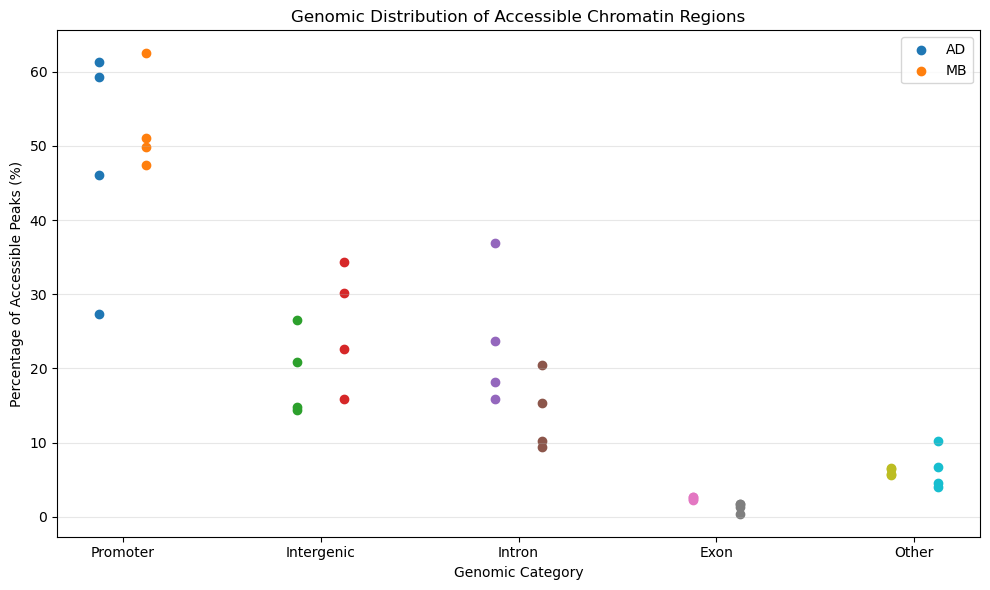

In [10]:
plot_data = percentages.copy()

fig, ax = plt.subplots(figsize=(10, 6))

categories_clean = [
    "Promoter",
    "Intergenic",
    "Intron",
    "Exon",
    "Other"
]

for i, category in enumerate(categories_clean):
    
    ad = plot_data.loc[
        plot_data["Condition"] == "AD",
        category + "_%"
    ]
    
    mb = plot_data.loc[
        plot_data["Condition"] == "MB",
        category + "_%"
    ]
    
    ax.scatter(
        np.full(len(ad), i - 0.12),
        ad,
        label="AD" if i == 0 else ""
    )
    
    ax.scatter(
        np.full(len(mb), i + 0.12),
        mb,
        label="MB" if i == 0 else ""
    )

ax.set_xticks(range(len(categories_clean)))
ax.set_xticklabels(categories_clean)

ax.set_ylabel("Percentage of Accessible Peaks (%)")
ax.set_xlabel("Genomic Category")
ax.set_title("Genomic Distribution of Accessible Chromatin Regions")

ax.legend()
ax.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

In [11]:
import pandas as pd

counts = pd.read_csv(
    "/home/ankita/chromatin_results/genomic_distribution_counts.tsv",
    sep="\t"
)

percentages = pd.read_csv(
    "/home/ankita/chromatin_results/genomic_distribution_percentages.tsv",
    sep="\t"
)

display(counts)
display(percentages)

,Sample,Condition,Total_Peaks,Promoter,Intergenic,Intron,Exon,Other
0,AD19,AD,11689,7158,1734,1853,281,663
1,AD20,AD,21475,9903,4483,5097,566,1426
2,AD21,AD,39422,10780,10467,14533,1074,2568
3,AD22,AD,12970,7695,1877,2354,290,754
4,MB48,MB,236,112,81,24,3,16
5,MB49,MB,235,117,71,22,1,24
6,MB50,MB,1987,1241,317,304,35,90
7,MB51,MB,8797,4491,1986,1805,155,360


,Sample,Condition,Total_Peaks,Promoter_%,Intergenic_%,Intron_%,Exon_%,Other_%
0,AD19,AD,11689,61.24,14.83,15.85,2.40,5.67
1,AD20,AD,21475,46.11,20.88,23.73,2.64,6.64
2,AD21,AD,39422,27.35,26.55,36.87,2.72,6.51
3,AD22,AD,12970,59.33,14.47,18.15,2.24,5.81
4,MB48,MB,236,47.46,34.32,10.17,1.27,6.78
5,MB49,MB,235,49.79,30.21,9.36,0.43,10.21
6,MB50,MB,1987,62.46,15.95,15.30,1.76,4.53
7,MB51,MB,8797,51.05,22.58,20.52,1.76,4.09


In [12]:
from statsmodels.stats.multitest import multipletests

categories = [
    "Promoter_%",
    "Intergenic_%",
    "Intron_%",
    "Exon_%",
    "Other_%"
]

results = []

for category in categories:
    ad = percentages.loc[percentages["Condition"] == "AD", category]
    mb = percentages.loc[percentages["Condition"] == "MB", category]

    U, p = mannwhitneyu(ad, mb, alternative="two-sided")

    results.append({
        "Category": category.replace("_%", ""),
        "AD_Mean": ad.mean(),
        "AD_SD": ad.std(),
        "MB_Mean": mb.mean(),
        "MB_SD": mb.std(),
        "U": U,
        "Raw_p": p
    })

stats = pd.DataFrame(results)

stats["FDR_p"] = multipletests(
    stats["Raw_p"],
    method="fdr_bh"
)[1]

display(stats.round(4))

,Category,AD_Mean,AD_SD,MB_Mean,MB_SD,U,Raw_p,FDR_p
0,Promoter,48.5075,15.6272,52.6900,6.6810,6.0,0.6857,0.8571
1,Intergenic,19.1825,5.7246,25.7650,8.1532,3.0,0.2000,0.3333
2,Intron,23.6500,9.4139,13.8375,5.1734,14.0,0.1143,0.2857
3,Exon,2.5000,0.2203,1.3050,0.6274,16.0,0.0294,0.1470
4,Other,6.1575,0.4884,6.4025,2.7984,8.0,1.0000,1.0000


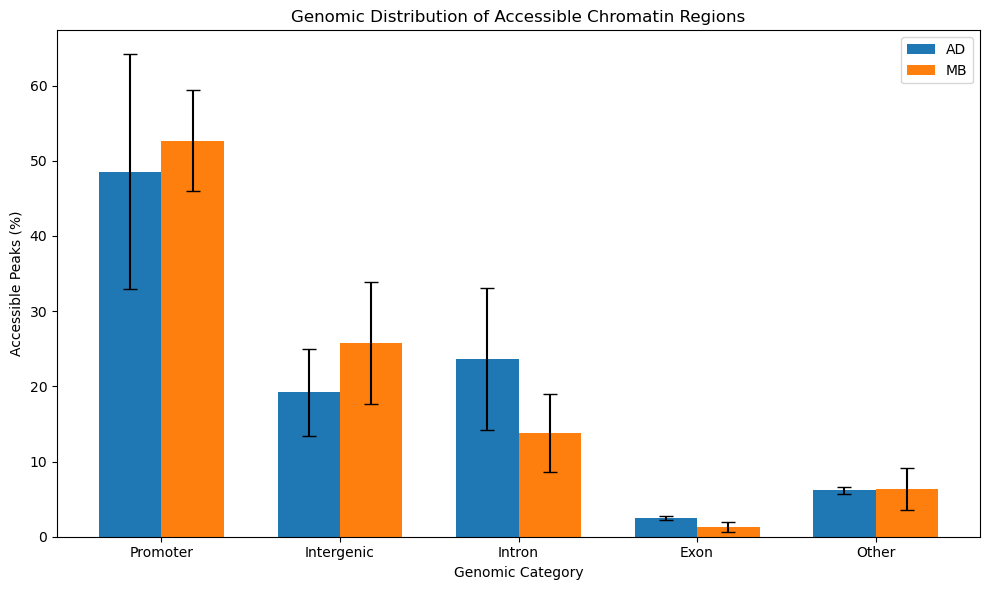

In [13]:
import matplotlib.pyplot as plt
import numpy as np

categories = stats["Category"]

x = np.arange(len(categories))
width = 0.35

fig, ax = plt.subplots(figsize=(10, 6))

ax.bar(
    x - width/2,
    stats["AD_Mean"],
    width,
    yerr=stats["AD_SD"],
    capsize=5,
    label="AD"
)

ax.bar(
    x + width/2,
    stats["MB_Mean"],
    width,
    yerr=stats["MB_SD"],
    capsize=5,
    label="MB"
)

ax.set_xlabel("Genomic Category")
ax.set_ylabel("Accessible Peaks (%)")
ax.set_title("Genomic Distribution of Accessible Chromatin Regions")
ax.set_xticks(x)
ax.set_xticklabels(categories)
ax.legend()

plt.tight_layout()
plt.show()

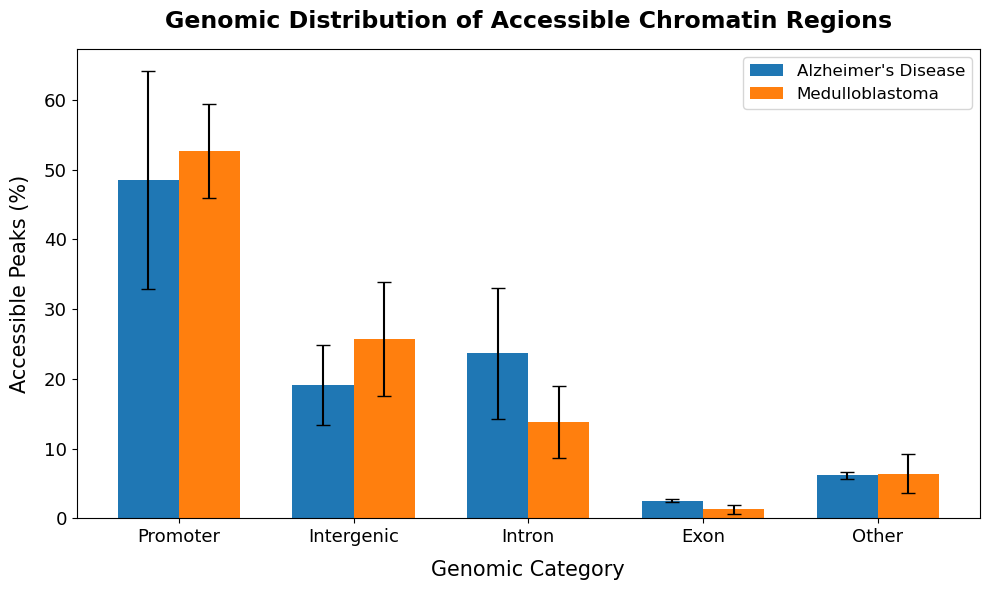

In [15]:

import matplotlib.pyplot as plt
import numpy as np

categories = stats["Category"]

x = np.arange(len(categories))
width = 0.35

fig, ax = plt.subplots(figsize=(10, 6))

ax.bar(
    x - width/2,
    stats["AD_Mean"],
    width,
    yerr=stats["AD_SD"],
    capsize=5,
    label="Alzheimer's Disease"
)

ax.bar(
    x + width/2,
    stats["MB_Mean"],
    width,
    yerr=stats["MB_SD"],
    capsize=5,
    label="Medulloblastoma"
)

# Increase font sizes
ax.set_xlabel("Genomic Category", fontsize=15, labelpad=10)
ax.set_ylabel("Accessible Peaks (%)", fontsize=15, labelpad=10)

ax.set_title(
    "Genomic Distribution of Accessible Chromatin Regions",
    fontsize=17,
    fontweight="bold",
    pad=15
)

# Increase category label size
ax.set_xticks(x)
ax.set_xticklabels(categories, fontsize=13)

# Increase Y-axis tick label size
ax.tick_params(axis="y", labelsize=13)

# Increase legend font size
ax.legend(fontsize=12, frameon=True)

plt.tight_layout()
plt.show()

In [16]:
plt.savefig(
    "/home/ankita/chromatin_results/Figure_5_2_genomic_distribution.pdf",
    bbox_inches="tight"
)

plt.savefig(
    "/home/ankita/chromatin_results/Figure_5_2_genomic_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

print("Figure 5.2 saved successfully.")

Figure 5.2 saved successfully.


<Figure size 640x480 with 0 Axes>

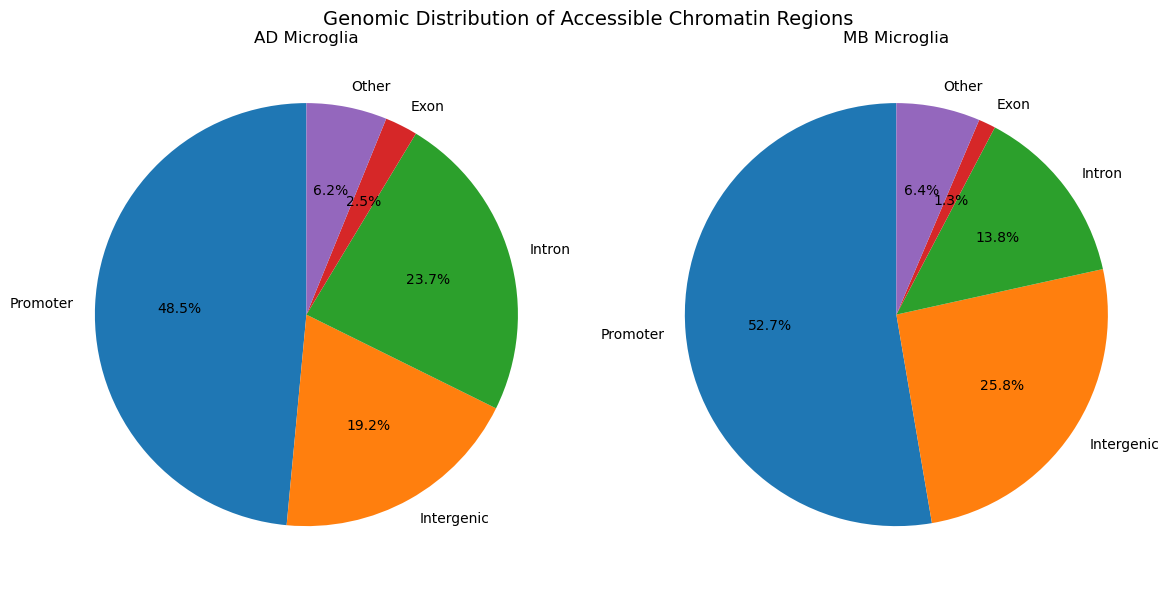

In [16]:
import matplotlib.pyplot as plt

categories = ["Promoter", "Intergenic", "Intron", "Exon", "Other"]

ad_values = [48.5075, 19.1825, 23.6500, 2.5000, 6.1575]
mb_values = [52.6900, 25.7650, 13.8375, 1.3050, 6.4025]

fig, axes = plt.subplots(1, 2, figsize=(12, 6))

# AD
axes[0].pie(
    ad_values,
    labels=categories,
    autopct="%1.1f%%",
    startangle=90
)
axes[0].set_title("AD Microglia")

# MB
axes[1].pie(
    mb_values,
    labels=categories,
    autopct="%1.1f%%",
    startangle=90
)
axes[1].set_title("MB Microglia")

fig.suptitle(
    "Genomic Distribution of Accessible Chromatin Regions",
    fontsize=14
)

plt.tight_layout()
plt.show()

In [22]:
import pandas as pd

file = "/home/ankita/chromatin_results/DifferentialPeaks.csv"

diff = pd.read_csv(file)

# Compare AD and MB concentrations
diff["Direction"] = diff.apply(
    lambda row: "AD-higher" if row["Conc_AD"] > row["Conc_MB"]
    else "MB-higher",
    axis=1
)

print("Total differential peaks:", len(diff))

print("\nDirection of differential accessibility:")
print(diff["Direction"].value_counts())

print("\nFDR summary:")
print(diff["FDR"].describe())

Total differential peaks: 1008

Direction of differential accessibility:
Direction
AD-higher    808
MB-higher    200
Name: count, dtype: int64

FDR summary:
count    1.008000e+03
mean     2.560514e-02
std      1.441648e-02
min      1.090289e-29
25%      1.341777e-02
50%      2.633078e-02
75%      3.822868e-02
max      4.993928e-02
Name: FDR, dtype: float64
